# 모의고사 2회 풀이

자료 이해 → 고정 분석 조건 → 문항별 풀이 근거 → 실행 코드 → 실제 결과의 순서로 읽으십시오. 전체를 위에서 아래로 실행합니다. 변수의 산업적 의미는 각 절의 사전을 따르며, 공식 정답이나 실제 현장 성능을 뜻하지 않습니다.

실제 결과를 모은 [해설](해설.md)과 [자료 사전](자료안내.md)을 함께 사용하십시오.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from IPython.display import display

# repository root 또는 회차 폴더에서 탐색; 경로를 하드코딩하지 않음.
ROOT = next(
    p
    for p in [Path.cwd()] + list(Path.cwd().parents)
    if (p / "기출문제/공통/reconstruction.py").exists()
)
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "기출문제/공통"))
from reconstruction import *
from matplotlib import font_manager

font_path = ROOT / "기출문제/공통/NanumGothic-Regular.ttf"
font_manager.fontManager.addfont(str(font_path))
plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False
HERE = ROOT / "기출문제" / "모의고사/2회"
DATA = HERE / "data"
OUT = HERE / "실행결과"
OUT.mkdir(exist_ok=True)


def load(name):
    return pd.read_csv(DATA / name)


print("데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님")

# 상황형 답안 기록 초기화
_SCENARIO_ROOT = next(
    p
    for p in [Path.cwd()] + list(Path.cwd().parents)
    if (p / "기출문제/공통/scenario_inference.py").is_file()
)
sys.path.insert(0, str(_SCENARIO_ROOT / "기출문제/공통"))
from scenario_inference import (
    reset_reports,
    set_question,
    report_test,
    report_anova,
    report_correlations,
    report_adf,
    report_residuals,
    report_regression_diagnostics,
)

reset_reports(OUT)

데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님


## 1. 입학 허가 수준 설명

**상황을 이해하기**

입학 상담에서 지원자의 사전 점수와 입학 허가 수준의 관계를 설명하는 과제입니다.

**관측 단위와 판단 목적**

한 행은 독립 지원자입니다. 연속 반응을 실제 합격/불합격과 혼동하지 않습니다. 지문에서 요구한 비교·예측·요약의 결과와 불확실성을 상황에 맞게 보고합니다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `Admission.csv / GRE` | 대학원 입학시험 점수 |
| `Admission.csv / TOEFL` | 영어능력시험 점수 |
| `Admission.csv / Univ_Rating` | 출신 대학 평가 지표 |
| `Admission.csv / SOP` | 학업계획서 평가 지표 |
| `Admission.csv / LOR` | 추천서 평가 지표 |
| `Admission.csv / CGPA` | 학업 성적 지표 |
| `Admission.csv / Research` | 연구 경험 유무 1/0 |
| `Admission.csv / Chance_of_Admit` | 입학 허가 수준 0~1의 연속 반응(실제 합격 라벨 아님) |

**고정 분석 조건**

입학 상담팀은 독립 지원자 자료에서 Chance_of_Admit와 지원 특성의 관계를 설명하려 한다. 연속 변수 간 선형 관계를 우선 살피되 관계가 인과 효과라는 보장은 없다.


### 1-1

**문제**

입학 허가 수준과 GRE·TOEFL·Univ_Rating·SOP·LOR·CGPA의 관계를 수치·그림으로 평가하시오. 관계 평가 방법과 가정을 선택하고 각 관계의 귀무·대립가설, p-value·기각 여부를 제시하시오. 다중 탐색의 한계도 설명하시오.

**풀이 근거와 읽는 순서**

연속 변수의 선형 관계를 Pearson으로 평가한다.

각 H0: rho=0, H1: rho≠0이며 상관 크기와 Holm 보정 p값을 구분한다.

명목 범주 코드에 수치 간격 의미를 부여하지 않는다.

**계산·해석 상세**

선형 관계의 방향·크기를 r로, H0:rho=0의 증거를 p값으로 구분합니다.

다수 상관 검정은 탐색으로 보고합니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

    feature         r      p_value
        GRE  0.577492 9.563125e-23
      TOEFL  0.528240 1.195124e-18
Univ_Rating  0.081874 2.062708e-01
        SOP -0.059005 3.627578e-01
        LOR  0.108662 9.304003e-02
       CGPA  0.836827 3.303858e-64


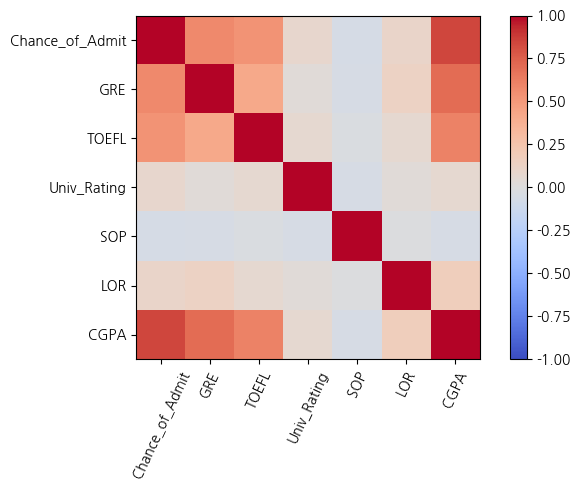

{
  "question": "1-1",
  "method": "Pearson 선형 상관: GRE",
  "H0": "rho(Chance_of_Admit,GRE)=0",
  "H1": "rho(Chance_of_Admit,GRE) != 0",
  "statistic": 0.5774915012910938,
  "p_value": 9.563124903236735e-23,
  "alpha": 0.05,
  "reject_H0": true,
  "assumptions": "독립 관측·선형 관계·이변량 정규 추론, 이상값 점검. 다중 비교 Holm 보정; 인과가 아님.",
  "conclusion": "귀무가설을 기각한다. Chance_of_Admit와 GRE 사이에 선형 관계가 있다는 통계적 근거가 있다.",
  "adjusted_p_value": 4.781562451618367e-22,
  "decision_basis": "Holm 보정 p값"
}
{
  "question": "1-1",
  "method": "Pearson 선형 상관: TOEFL",
  "H0": "rho(Chance_of_Admit,TOEFL)=0",
  "H1": "rho(Chance_of_Admit,TOEFL) != 0",
  "statistic": 0.5282400368607214,
  "p_value": 1.1951240651199492e-18,
  "alpha": 0.05,
  "reject_H0": true,
  "assumptions": "독립 관측·선형 관계·이변량 정규 추론, 이상값 점검. 다중 비교 Holm 보정; 인과가 아님.",
  "conclusion": "귀무가설을 기각한다. Chance_of_Admit와 TOEFL 사이에 선형 관계가 있다는 통계적 근거가 있다.",
  "adjusted_p_value": 4.780496260479797e-18,
  "decision_basis": "Holm 보정 p값"
}
{
  "question": "1-1",
  "method": 

In [2]:
set_question("1-1")
admit = load("Admission.csv")
numeric_correlations(
    admit, "Chance_of_Admit", ["GRE", "TOEFL", "Univ_Rating", "SOP", "LOR", "CGPA"]
)

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
report_correlations(
    admit, "Chance_of_Admit", ["GRE", "TOEFL", "Univ_Rating", "SOP", "LOR", "CGPA"]
)

### 1-2

**문제**

앞 특성과 Research를 후보로 입학 허가 수준의 설명 모형을 구성하시오. 변수 추가·제거 기준, 추정식·잔차 점검과 선택 후 해석의 한계를 제시하시오.

**풀이 근거와 읽는 순서**

AIC 선택 후 잔차의 정규성·등분산을 진단한다.

선택 후 계수 p값은 탐색적이며 전체 선택 절차를 무시한 확증 근거로 쓰지 않는다.

**계산·해석 상세**

원문 Shapiro p=.09를 기각으로 해석한 오류를 수정합니다.

p>=.05에서는 정규성 귀무가설을 기각하지 못합니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

선택 변수: ['CGPA']
   step features         AIC
0     1     CGPA -722.230836
                            OLS Regression Results                            
Dep. Variable:        Chance_of_Admit   R-squared:                       0.700
Model:                            OLS   Adj. R-squared:                  0.699
Method:                 Least Squares   F-statistic:                     556.1
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           3.30e-64
Time:                        11:26:52   Log-Likelihood:                 363.12
No. Observations:                 240   AIC:                            -722.2
Df Residuals:                     238   BIC:                            -715.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------

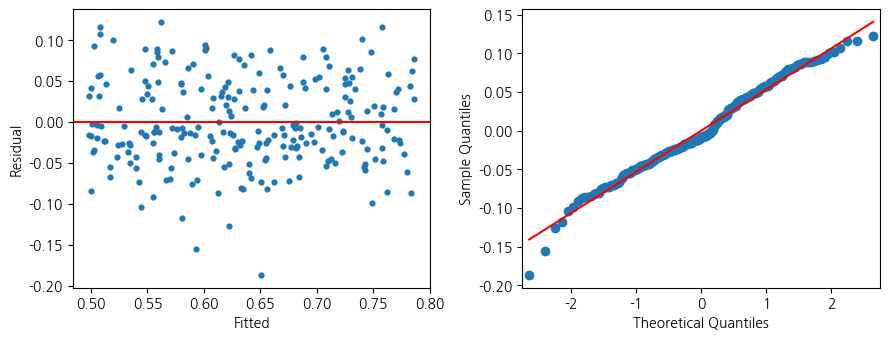

{
  "question": "1-2",
  "method": "Shapiro-Wilk 잔차 진단",
  "H0": "잔차 분포가 정규이다",
  "H1": "잔차 분포가 정규가 아니다",
  "statistic": 0.9857776876905661,
  "p_value": 0.017136396086197856,
  "alpha": 0.05,
  "reject_H0": true,
  "assumptions": "선택된 모형의 잔차를 이용한 탐색 진단이며 선택 후 추론의 한계가 있다.",
  "conclusion": "귀무가설을 기각한다. 잔차 분포가 정규에서 벗어난다는 통계적 근거가 있다."
}
{
  "question": "1-2",
  "method": "Breusch-Pagan 잔차 진단",
  "H0": "오차 분산이 일정하다",
  "H1": "오차 분산이 일정하지 않다",
  "statistic": 0.9882120722145604,
  "p_value": 0.32017975261341974,
  "alpha": 0.05,
  "reject_H0": false,
  "assumptions": "독립 관측과 지정된 분산 설명 구조에 의존하는 점근적 진단이다.",
  "conclusion": "귀무가설을 기각하지 못한다. 잔차에 이분산이 존재한다는 통계적 근거가 충분하지 않다. 귀무가설의 참을 입증한 것은 아니다.",
  "df": 1
}


In [3]:
set_question("1-2")
admit_model = select_ols(
    admit,
    "Chance_of_Admit",
    ["GRE", "TOEFL", "Univ_Rating", "SOP", "LOR", "CGPA", "Research"],
    "stepwise",
)
residual_diagnostics(admit_model)

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
report_regression_diagnostics(admit_model)

## 2. 승객 생존 예측

**상황을 이해하기**

승객의 사전 속성으로 생존 사건을 예측하는 학습 과제입니다.

**관측 단위와 판단 목적**

한 행은 승객입니다. 식별 가능한 미래 사건을 예측 입력에 섞지 않고 정한 분할을 재사용합니다. 지문에서 요구한 비교·예측·요약의 결과와 불확실성을 상황에 맞게 보고합니다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `titanic.csv / pclass` | 객실 등급 1/2/3(범주) |
| `titanic.csv / sex` | 성별 범주 |
| `titanic.csv / sibsp` | 동승 형제자매·배우자 수 |
| `titanic.csv / parch` | 동승 부모·자녀 수 |
| `titanic.csv / fare` | 운임 지표 |
| `titanic.csv / embarked` | 승선 항구 범주 |
| `titanic.csv / age` | 나이 |
| `titanic.csv / cabin` | 객실 정보(문자열/결측) |
| `titanic.csv / survived` | 생존=1, 사망=0 |

**고정 분석 조건**

별도 승객 자료로 survived를 예측하려 한다. 이 대문항의 전처리와 모든 비교는 같은 7:3 분할·시드 12345를 사용한다. pclass·sex·sibsp·parch·fare·embarked를 예측 특성으로 사용한다.


### 2-1

**문제**

빈 문자열·변수 자료형·결측을 점검하시오. 수치형 중앙값·범주형 최빈값 대치와 연령 10세 구간 age_1(0~8)을 구성하되 대치 기준은 학습 자료에서만 구하시오. 범위 밖 연령을 점검하시오.

**풀이 근거와 읽는 순서**

문제의 전처리 완료 후 분할 순서를 그대로 쓰면 test 정보가 대치값에 들어갑니다.

빈문자·타입·구간은 유지하고 통계량 적합은 학습으로 한정합니다.

실제 분류 입력의 대치는 Pipeline에서 수행합니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [4]:
set_question("2-1")
titanic = load("titanic.csv").replace("", np.nan)
titanic["pclass"] = titanic.pclass.astype("category")
titanic["sex"] = titanic.sex.astype("category")
ids_train, ids_test = train_test_split(
    np.arange(len(titanic)),
    test_size=0.3,
    random_state=12345,
    stratify=titanic.survived,
)
median_age = titanic.iloc[ids_train].age.median()
titanic["age_imputed"] = titanic.age.fillna(median_age)
titanic["age_1"] = pd.cut(
    titanic.age_imputed, bins=list(range(0, 91, 10)), labels=list(range(9)), right=False
)
print(titanic[["age", "age_imputed", "age_1"]].head())
print("train age median:", median_age)

         age  age_imputed age_1
0  68.153239    68.153239     6
1  15.791815    15.791815     1
2  37.333111    37.333111     3
3  65.214912    65.214912     6
4  45.493908    45.493908     4
train age median: 43.11805070558041


### 2-2

**문제**

고정한 분할로 서로 다른 분류 모형 3개 이상을 적합하시오. 각 모형의 시험 예측 CSV를 제출하고 전처리·비교 조건이 일치함을 확인하시오.

**풀이 근거와 읽는 순서**

R set.seed와 NumPy random_state는 같은 난수열을 보장하지 않습니다.

Python 재현 시드만 12345로 유지합니다.

Logistic/RF/GradientBoosting 세 모델의 동일 보류 예측 CSV를 저장합니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

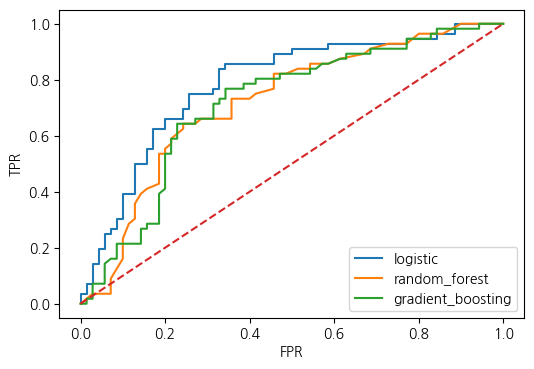

               model  accuracy  f1_weighted   ROC_AUC
0           logistic  0.722222     0.723011  0.783418
1      random_forest  0.690476     0.690180  0.718495
2  gradient_boosting  0.698413     0.698413  0.715179


In [5]:
set_question("2-2")
titanic_scores, titanic_models, train, test = classify(
    titanic,
    "survived",
    ["pclass", "sex", "sibsp", "parch", "fare", "embarked"],
    OUT,
    seed=12345,
)

### 2-3

**문제**

같은 시험 자료에서 정확도와 ROC-AUC·ROC 곡선을 비교하시오. 양성 확률의 필요성과 이 자료로 다시 튜닝할 때의 문제를 설명하시오.

**풀이 근거와 읽는 순서**

ROC는 이산 클래스가 아니라 predict_proba의 양성 확률로 계산했습니다.

위 셀의 동일 holdout 그래프와 AUC를 보고하며 test 최고를 새 튜닝의 근거로 쓰지 않습니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [6]:
set_question("2-3")
print(titanic_scores)
print(
    "보류 최고 accuracy 모델:",
    titanic_scores.loc[titanic_scores.accuracy.idxmax(), "model"],
)

               model  accuracy  f1_weighted   ROC_AUC
0           logistic  0.722222     0.723011  0.783418
1      random_forest  0.690476     0.690180  0.718495
2  gradient_boosting  0.698413     0.698413  0.715179
보류 최고 accuracy 모델: logistic


## 3. 연설문 관심 주제

**상황을 이해하기**

문서에서 관심 단어의 빈도와 날짜별 관심을 요약합니다.

**관측 단위와 판단 목적**

한 행은 문서 한 건입니다. 품사는 제공된 학습 사전의 표시에 한정됩니다. 지문에서 요구한 비교·예측·요약의 결과와 불확실성을 상황에 맞게 보고합니다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `speech.csv / date` | 문서 작성 날짜 |
| `speech.csv / text` | 분석할 문서 내용 |
| `lexicon.csv / word` | 학습용 품사 사전에 등록된 단어 |
| `lexicon.csv / pos` | Noun=명사, Adjective=형용사 |

**고정 분석 조건**

별도의 합성 연설문과 명시 품사 사전이 주어진다. 문서별 맥락을 유지한 관심 단어 요약이 목적이다.


### 3-1

**문제**

숫자·특수문자를 정제하고 원문과 정제 문서의 대응을 확인하시오. 삭제로 손실될 수 있는 정보를 설명하시오.

**풀이 근거와 읽는 순서**

문서별 구분을 유지해 숫자·특수 기호만 제거합니다.

합성 자료의 내용·빈도가 실제 취임사의 결과는 아닙니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [7]:
set_question("3-1")
speech = load("speech.csv")
lexicon = load("lexicon.csv")
speech["clean"] = speech.text.map(clean_text)
print(speech[["text", "clean"]].head())

                              text                     clean
0  공구 가족 민주주의 맛 민주주의 영화 빠르다 123 !@  공구 가족 민주주의 맛 민주주의 영화 빠르다
1      배송 여행 호텔 배송 여행 배송 좋다 123 !@      배송 여행 호텔 배송 여행 배송 좋다
2      가족 학교 행복 공구 호텔 공구 좋다 123 !@      가족 학교 행복 공구 호텔 공구 좋다
3   공구 공구 학교 민주주의 영화 여행 즐겁다 123 !@   공구 공구 학교 민주주의 영화 여행 즐겁다
4      배송 공구 배송 호텔 행복 공구 좋다 123 !@      배송 공구 배송 호텔 행복 공구 좋다


### 3-2(보충)

**문제**

사전에서 명사로 지정된 어휘를 추출하고 빈도 상위 10개를 시각화하시오. 빈도 순위를 문서의 의미나 실제 여론으로 단정할 수 없는 이유를 설명하시오.

**풀이 근거와 읽는 순서**

첨부 풀이 코드의 명사 추출·빈도 그래프에서 보충했습니다.

일반 원문 형태소 분석기 대체가 아닙니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

   word  count
0    학교     47
1    공구     40
2    호텔     39
3    행복     39
4  민주주의     35
5    영화     34
6    가족     33
7    배송     33
8    여행     33
9     맛     27


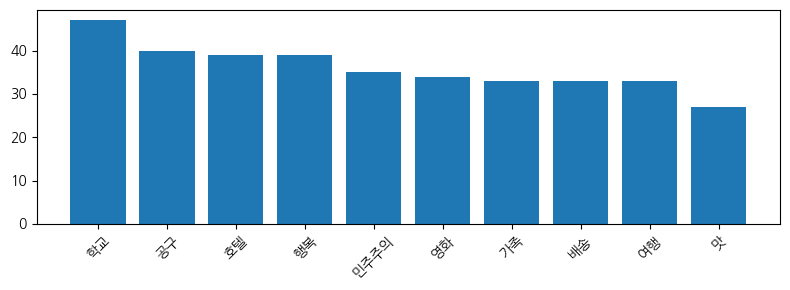

In [8]:
set_question("3-2(보충)")
word_plot(lexical_pos(speech.text, lexicon), 10)